# Axynetra: a complete supervised ML experiment
**Multi-Class Attack Classification — CSMA Option 4**

This notebook explains each stage rather than hiding training inside one function.
All ML and plotting code is visible here, using pandas, NumPy, scikit-learn and
Matplotlib directly. No application helper modules are imported.

**Saved outputs are synthetic demonstrations, not UNSW-NB15 benchmark results.**
The implemented models are supervised classifiers; no autoencoder is used.
Restart the kernel and Run All after changing configuration. Do not repeatedly
inspect test scores to tune models. Only the validation set selects the winner.


## 1. Imports and reproducibility
Output: package versions, random seed and the ten supported categories.


In [1]:
from pathlib import Path
import json
import platform
import hashlib
import importlib.metadata
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_classification
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve)

ROOT = Path.cwd()
pd.set_option('display.max_columns', 16)
SEED = 42
CLASSES = ['Normal', 'Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers',
           'Generic', 'Reconnaissance', 'Shellcode', 'Worms']
LEAKAGE_COLUMNS = {'attack_cat', 'label', 'id'}
SEVERITY = {'Normal': 0, 'Analysis': 2, 'Backdoor': 5, 'DoS': 4, 'Exploits': 5,
            'Fuzzers': 2, 'Generic': 3, 'Reconnaissance': 3, 'Shellcode': 5, 'Worms': 5}
versions = {name: importlib.metadata.version(name)
            for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']}
print('Python:', platform.python_version(), '| Seed:', SEED)
display(pd.Series(versions, name='version').to_frame())
print('Classes:', ', '.join(CLASSES))


Python: 3.14.6 | Seed: 42


,version
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2


Classes: Normal, Analysis, Backdoor, DoS, Exploits, Fuzzers, Generic, Reconnaissance, Shellcode, Worms


## 2. Configure and load data
`SMOKE_TEST=True` explicitly generates a reproducible synthetic demonstration.
Set it to `False` only after placing the two real CSVs in `data/`.
Missing real files cause an error; there is no automatic synthetic fallback.
Set row limits to zero for the full supplied split. Record subsampling in results.
Output: run type, source fingerprints and dataset sizes.


In [2]:
SMOKE_TEST = True
MAX_TRAIN = 50000
MAX_TEST = 20000
VAL_FRACTION = 0.20
TRAIN_PATH = ROOT / 'data' / 'UNSW_NB15_training-set.csv'
TEST_PATH = ROOT / 'data' / 'UNSW_NB15_testing-set.csv'
OUT = ROOT / 'outputs' / 'notebook'
OUT.mkdir(parents=True, exist_ok=True)
# Invalidate completion marker before beginning a new notebook experiment.
(OUT / 'run_metadata.json').unlink(missing_ok=True)

def fingerprint(path):
    with path.open('rb') as source:
        return hashlib.file_digest(source, 'sha256').hexdigest()

if SMOKE_TEST:
    X, y = make_classification(n_samples=2200, n_features=22, n_informative=17,
                               n_redundant=3, n_classes=10, n_clusters_per_class=1,
                               flip_y=0.08, random_state=SEED)
    data = pd.DataFrame(X, columns=[f'feature_{i:02d}' for i in range(22)])
    data['proto'] = np.where(data.feature_01 > 0, 'tcp', 'udp')
    data['service'] = np.where(data.feature_05 > 0, 'dns', 'http')
    data['attack_cat'] = np.array(CLASSES)[y]
    train = data.iloc[:1700].copy().reset_index(drop=True)
    test = data.iloc[1700:].copy().reset_index(drop=True)
    provenance = {'source': 'Synthetic sklearn.make_classification; not UNSW-NB15'}
    RUN_LABEL = 'SYNTHETIC DEMONSTRATION — NOT UNSW-NB15 PERFORMANCE'
else:
    if not TRAIN_PATH.is_file() or not TEST_PATH.is_file():
        raise FileNotFoundError('Download the real train/test CSVs into data/ before disabling SMOKE_TEST.')
    train = pd.read_csv(TRAIN_PATH)
    test = pd.read_csv(TEST_PATH)
    provenance = {'source': 'Supplied CSV files; origin not independently verified',
                  'train_sha256': fingerprint(TRAIN_PATH), 'test_sha256': fingerprint(TEST_PATH)}
    RUN_LABEL = 'SUPPLIED CSV EXPERIMENT — VERIFY DATASET ORIGIN'
print(RUN_LABEL)
display(pd.DataFrame({'split': ['training', 'held-out test'], 'rows': [len(train), len(test)],
                      'columns': [train.shape[1], test.shape[1]]}))
display(pd.Series(provenance, name='provenance').to_frame())


SYNTHETIC DEMONSTRATION — NOT UNSW-NB15 PERFORMANCE


,split,rows,columns
0,training,1700,25
1,held-out test,500,25


,provenance
source,Synthetic sklearn.make_classification; not UNS...


## 3. Inspect training data (EDA)
Explore training records only. These views explain the available feature types,
missing values and class imbalance. They do not fit a transformer or use test
performance for design decisions. Synthetic `feature_XX` columns are not actual
UNSW-NB15 feature names. Real benchmark features include flow duration/protocol.
Output: training preview, schema, numeric summary, missingness and class chart.


,feature_00,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,...,feature_17,feature_18,feature_19,feature_20,feature_21,proto,service,attack_cat
0,-1.908213,-0.348710,-1.419997,0.769909,7.355246,4.583465,-0.073025,5.797250,...,3.235956,0.562370,1.115698,-5.592283,-5.768337,udp,dns,Normal
1,-6.593633,-1.359880,-2.429948,-2.093032,3.420735,1.689573,-0.113449,0.391350,...,-0.348546,-0.439230,-1.568530,2.244281,-3.042886,udp,dns,Fuzzers
2,-3.301668,-0.137480,-1.390392,1.320043,1.249469,-0.234175,1.678411,-1.822771,...,-1.111000,1.287634,-0.954316,1.063146,0.706567,udp,http,Shellcode
3,0.490170,-1.520170,-4.255045,0.866663,0.438768,-2.403597,-4.569701,3.652573,...,0.431467,-2.008559,0.692979,-4.339375,-4.292943,udp,http,Reconnaissance
4,-6.992836,3.536532,0.763930,2.927645,0.469779,0.812744,4.111605,1.834025,...,-1.687506,-0.312134,0.342236,2.197313,-1.391428,tcp,dns,Exploits


,dtype,missing,unique
feature_00,float64,0,1700
feature_01,float64,0,1700
feature_02,float64,0,1700
feature_03,float64,0,1700
feature_04,float64,0,1700
feature_05,float64,0,1700
feature_06,float64,0,1700
feature_07,float64,0,1700
feature_08,float64,0,1700
feature_09,float64,0,1700


,count,mean,std,min,25%,50%,75%,max
feature_00,1700.0,-1.305976,5.997519,-19.445522,-5.146687,-1.279589,2.623363,20.657216
feature_01,1700.0,0.051824,0.995906,-3.018198,-0.615052,0.033092,0.709549,3.536532
feature_02,1700.0,-0.481173,2.419141,-8.600183,-2.066473,-0.448539,1.096815,8.251693
feature_03,1700.0,0.025648,1.006236,-3.631539,-0.671004,0.049630,0.747397,3.222928
feature_04,1700.0,0.227240,2.524322,-8.089194,-1.523610,0.161988,1.975620,7.424743
feature_05,1700.0,0.315800,2.651487,-8.334247,-1.408959,0.329198,2.191450,10.606447
feature_06,1700.0,0.157800,2.639931,-9.148302,-1.641984,0.063408,1.944173,9.166004
feature_07,1700.0,0.069193,2.615243,-9.561063,-1.696108,0.115570,1.766644,8.279699
feature_08,1700.0,0.031664,2.509182,-8.402425,-1.558313,-0.001273,1.672732,8.306144
feature_09,1700.0,-0.964393,6.748605,-23.094591,-5.296590,-1.010321,3.251588,27.436429


,training_rows
attack_cat,
Exploits,183
Analysis,179
Shellcode,174
Reconnaissance,170
Fuzzers,168
Backdoor,168
Normal,166
DoS,164
Worms,164


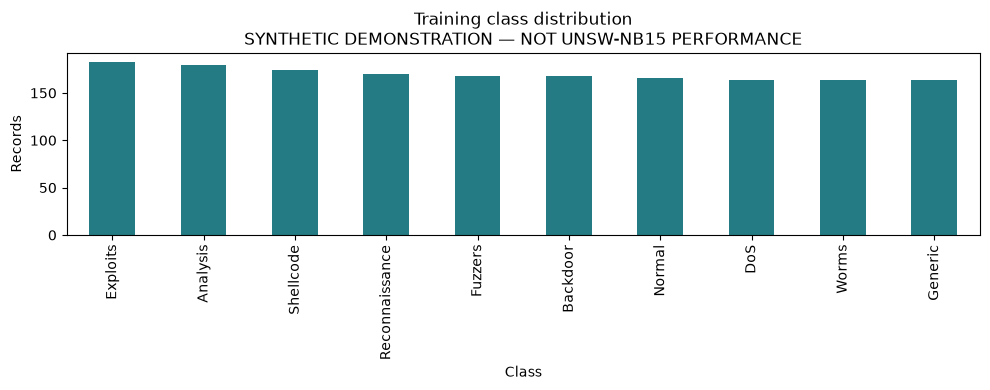

In [3]:
display(train.head())
schema = pd.DataFrame({'dtype': train.dtypes.astype(str), 'missing': train.isna().sum(),
                       'unique': train.nunique(dropna=True)})
display(schema)
display(train.describe(include='number').T)
if 'attack_cat' not in train:
    raise ValueError('Training CSV must contain the attack_cat target column.')
class_counts = train.attack_cat.value_counts(dropna=False)
display(class_counts.rename('training_rows').to_frame())
fig, ax = plt.subplots(figsize=(10, 4))
class_counts.plot.bar(ax=ax, color='#247b83')
ax.set(title=f'Training class distribution\n{RUN_LABEL}', ylabel='Records', xlabel='Class')
fig.tight_layout()
fig.savefig(OUT / 'training_class_distribution.png', dpi=150)
display(fig)
plt.close(fig)


## 4. Validate inputs and prevent identifiable leakage
Exclude the target `attack_cat`, binary `label`, and row `id` from predictors.
Reject missing labels, infinite measurements, duplicate training predictors and
exact train/test overlap. Investigate duplicate records before changing the split;
never silently deduplicate an official benchmark and claim its original protocol.
These checks do not establish the absence of every possible form of leakage.
Output: accepted predictor list and successful input checks, or an actionable error.


In [4]:
label_map = {label.lower(): label for label in CLASSES}
label_map['backdoors'] = 'Backdoor'
for frame in [train, test]:
    names = [str(column).strip().lower() for column in frame.columns]
    if len(names) != len(set(names)) or any(
            re.fullmatch(r'(attack_cat|label|id)\.\d+', name) for name in names):
        raise ValueError('Duplicate or ambiguous CSV columns may cause target leakage.')
features = [column for column in train if column.strip().lower() not in LEAKAGE_COLUMNS]
if not features or any(column not in test for column in features):
    raise ValueError('Training/test CSVs need matching predictor columns.')
for split_name, frame in [('training', train), ('test', test)]:
    if frame.empty or 'attack_cat' not in frame:
        raise ValueError(f'{split_name} must be nonempty and contain attack_cat.')
    cleaned = frame.attack_cat.astype('string').str.strip().str.lower()
    frame['attack_cat'] = cleaned.map(label_map)
    if not frame.attack_cat.isin(CLASSES).all():
        raise ValueError(f'{split_name} contains missing or unknown attack categories.')
    numeric = frame[features].select_dtypes(include='number')
    if np.isinf(numeric.to_numpy(dtype=float)).any():
        raise ValueError(f'{split_name} has infinite predictors; investigate them first.')
train_hashes = pd.util.hash_pandas_object(train[features], index=False)
test_hashes = pd.util.hash_pandas_object(test[features], index=False)
if train_hashes.isin(test_hashes).any():
    raise ValueError('Identical predictors occur in both training and test data.')
if train.duplicated(subset=features).any():
    raise ValueError('Resolve duplicate training predictors before validation splitting.')
if train.attack_cat.nunique() < 2:
    raise ValueError('Training needs at least two classes.')
# Optional sampling happens after full-input overlap checks. Explicit per-class
# allocations enforce the requested size without accidentally dropping rare classes.
for split_name, limit in [('train', MAX_TRAIN), ('test', MAX_TEST)]:
    frame = train if split_name == 'train' else test
    if limit > 0 and len(frame) > limit:
        groups = list(frame.groupby('attack_cat', sort=False))
        if limit < len(groups):
            raise ValueError('Row limit is too small to represent all classes.')
        sizes = np.array([len(group) for _, group in groups])
        minimum = 2 if limit >= 2 * len(groups) else 1
        counts = np.minimum(sizes, minimum)
        ideal = sizes * limit / len(frame)
        while counts.sum() < limit:
            deficits = np.where(counts < sizes, ideal - counts, -np.inf)
            counts[np.argmax(deficits)] += 1
        sampled = pd.concat([group.sample(n=int(count), random_state=SEED)
                             for (_, group), count in zip(groups, counts)], ignore_index=True)
        frame = sampled.sample(frac=1, random_state=SEED).reset_index(drop=True)
        if split_name == 'train':
            train = frame
        else:
            test = frame
assert not set(c.strip().lower() for c in features) & LEAKAGE_COLUMNS
print('Input checks passed. Predictor count:', len(features))
print('Excluded:', ', '.join(sorted(LEAKAGE_COLUMNS)))
print('Predictors:', ', '.join(features))


Input checks passed. Predictor count: 24
Excluded: attack_cat, id, label
Predictors: feature_00, feature_01, feature_02, feature_03, feature_04, feature_05, feature_06, feature_07, feature_08, feature_09, feature_10, feature_11, feature_12, feature_13, feature_14, feature_15, feature_16, feature_17, feature_18, feature_19, feature_20, feature_21, proto, service


## 5. Create fit-training and validation subsets
Stratify within the training data, approximately 80/20. Classes with at least two
examples retain one in each subset; singleton classes stay in fit-training with a
documented fallback. Integer rounding means the ratio is approximate.
Output: fit/validation sizes and class coverage. The held-out test stays separate.


In [5]:
if not .05 <= VAL_FRACTION <= .5:
    raise ValueError('VAL_FRACTION must be between 0.05 and 0.50.')
train = train.reset_index(drop=True)
fit_parts, validation_parts, fallbacks = [], [], []
for label, group in train.groupby('attack_cat', sort=False):
    if len(group) == 1:
        fit_parts.append(group)
        fallbacks.append(f'{label}: singleton kept in fit-training only')
    else:
        n_validation = max(1, min(len(group)-1, round(len(group) * VAL_FRACTION)))
        held_for_validation = group.sample(n=n_validation, random_state=SEED)
        validation_parts.append(held_for_validation)
        fit_parts.append(group.drop(index=held_for_validation.index))
fit = pd.concat(fit_parts, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
validation = (pd.concat(validation_parts, ignore_index=True).sample(frac=1, random_state=SEED)
              .reset_index(drop=True)) if validation_parts else train.iloc[:0].copy()
split_info = {'val_fraction': VAL_FRACTION, 'fit_train_rows': len(fit), 'val_rows': len(validation),
              'fit_train_class_counts': fit.attack_cat.value_counts().to_dict(),
              'val_class_counts': validation.attack_cat.value_counts().to_dict(),
              'rare_class_fallbacks': fallbacks}
if validation.empty:
    raise ValueError('No validation rows; supply more training examples.')
X_fit, y_fit = fit[features], fit.attack_cat
X_val, y_val = validation[features], validation.attack_cat
X_train, y_train = train[features], train.attack_cat
X_test, y_test = test[features], test.attack_cat
display(pd.DataFrame({'fit_training': y_fit.value_counts(), 'validation': y_val.value_counts()})
        .reindex(CLASSES).fillna(0).astype(int))
print(f'Fit-training: {len(fit)} | Validation: {len(validation)} | Held-out test: {len(test)}')
print('Rare-class fallbacks:', split_info['rare_class_fallbacks'] or 'None')


,fit_training,validation
attack_cat,,
Normal,133,33
Analysis,143,36
Backdoor,134,34
DoS,131,33
Exploits,146,37
Fuzzers,134,34
Generic,131,33
Reconnaissance,136,34
Shellcode,139,35


Fit-training: 1358 | Validation: 342 | Held-out test: 500
Rare-class fallbacks: None


## 6. Define preprocessing and candidate classifiers
Numeric features: median imputation then standardization.
Categorical features: most-frequent imputation then one-hot encoding, ignoring
categories unseen during fitting. The target is never included in this transform.
Each model receives its own preprocessing pipeline, fitted only on fit-training.
Class weighting helps address imbalance. There is no learned autoencoder stage.
Output: preprocessing structure and the four model configurations.


In [6]:
categorical_columns = X_fit.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
numeric_columns = [column for column in features if column not in categorical_columns]
numeric_transformer = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
categorical_transformer = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_transformer, numeric_columns),
    ('categorical', categorical_transformer, categorical_columns),
], sparse_threshold=.3)
display(preprocessor)
candidates = {
    'Decision Tree': DecisionTreeClassifier(max_depth=22, min_samples_leaf=4,
                                           class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=90, max_depth=25, min_samples_leaf=2,
                                            class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
    'Extra Trees': ExtraTreesClassifier(n_estimators=90, min_samples_leaf=2,
                                       class_weight='balanced', n_jobs=-1, random_state=SEED),
    'Logistic Regression': LogisticRegression(max_iter=800, class_weight='balanced',
                                               solver='lbfgs', random_state=SEED),
}
display(pd.DataFrame([{'model': name, 'estimator': repr(estimator)}
                      for name, estimator in candidates.items()]))


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

,model,estimator
0,Decision Tree,DecisionTreeClassifier(class_weight='balanced'...
1,Random Forest,RandomForestClassifier(class_weight='balanced_...
2,Extra Trees,"ExtraTreesClassifier(class_weight='balanced', ..."
3,Logistic Regression,"LogisticRegression(class_weight='balanced', ma..."


## 7. Train models and compare validation results
Every candidate fits on fit-training and is measured on validation. Macro F1 gives
equal weight to the ten defined classes. ROC-AUC uses probability scores in a
one-vs-rest comparison, aligned to `classifier.classes_`, not predicted labels.
Full macro AUC is undefined unless all ten class AUCs can be computed; the separately
named supported-class mean includes a coverage count. It is not a substitute for
full ten-class AUC. Output: four-model validation leaderboard and comparison chart.


,model,split,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,roc_auc_ovr_macro_supported,roc_auc_defined_classes,roc_auc_total_classes,selected_for_test
0,Extra Trees,validation,0.669591,0.677413,0.668789,0.669486,0.669654,0.894293,0.894293,10,10,True
1,Random Forest,validation,0.625731,0.627891,0.625188,0.624573,0.625060,0.902001,0.902001,10,10,False
2,Logistic Regression,validation,0.529240,0.529311,0.529172,0.525400,0.525443,0.864637,0.864637,10,10,False
3,Decision Tree,validation,0.304094,0.309637,0.304168,0.305730,0.305907,0.651713,0.651713,10,10,False


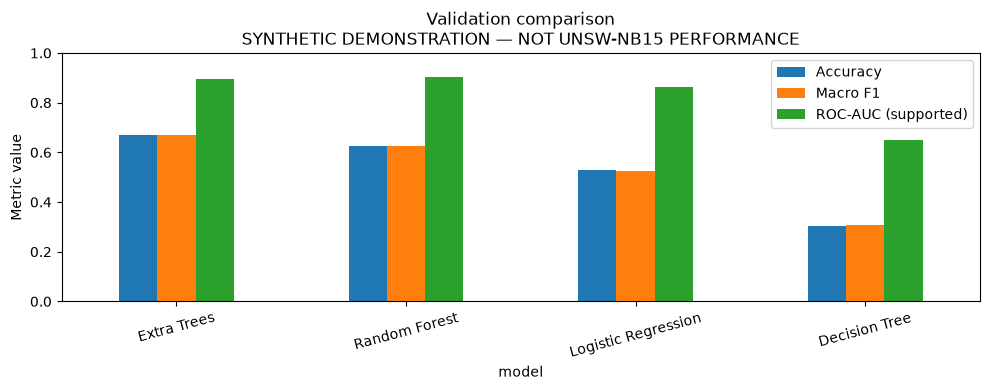

In [7]:
fitted = {}
validation_rows, validation_auc_rows = [], []
for name, estimator in candidates.items():
    pipeline = Pipeline([('features', clone(preprocessor)),
                         ('classifier', clone(estimator))])
    pipeline.fit(X_fit, y_fit)
    predictions = pipeline.predict(X_val)
    metrics = {'model': name, 'split': 'validation',
               'accuracy': float(accuracy_score(y_val, predictions)),
               'macro_precision': float(precision_score(y_val, predictions, labels=CLASSES, average='macro', zero_division=0)),
               'macro_recall': float(recall_score(y_val, predictions, labels=CLASSES, average='macro', zero_division=0)),
               'macro_f1': float(f1_score(y_val, predictions, labels=CLASSES, average='macro', zero_division=0)),
               'weighted_f1': float(f1_score(y_val, predictions, average='weighted', zero_division=0))}
    probabilities = pipeline.predict_proba(X_val)
    learned_classes = pipeline.named_steps['classifier'].classes_.tolist()
    auc_rows = []
    for label in CLASSES:
        binary = y_val.to_numpy() == label
        positives = int(binary.sum())
        reason = ('no_positive_examples' if positives == 0 else
                  'no_negative_examples' if positives == len(y_val) else
                  'class_not_learned' if label not in learned_classes else '')
        auc = None if reason else float(roc_auc_score(binary, probabilities[:, learned_classes.index(label)]))
        auc_rows.append({'class': label, 'support': positives, 'roc_auc_ovr': auc, 'status': reason or 'defined'})
    defined = [row['roc_auc_ovr'] for row in auc_rows if row['roc_auc_ovr'] is not None]
    metrics.update(roc_auc_ovr_macro=float(np.mean(defined)) if len(defined) == len(CLASSES) else None,
                   roc_auc_ovr_macro_supported=float(np.mean(defined)) if defined else None,
                   roc_auc_defined_classes=len(defined), roc_auc_total_classes=len(CLASSES))
    validation_rows.append(metrics)
    validation_auc_rows.extend(dict(row, model=name, split='validation') for row in auc_rows)
    fitted[name] = pipeline
leaderboard = pd.DataFrame(validation_rows).sort_values(
    ['macro_f1', 'weighted_f1', 'accuracy'], ascending=False).reset_index(drop=True)
best_name = leaderboard.iloc[0]['model']
leaderboard['selected_for_test'] = leaderboard.model == best_name
display(leaderboard)
fig, ax = plt.subplots(figsize=(10, 4))
leaderboard.set_index('model')[['accuracy', 'macro_f1', 'roc_auc_ovr_macro_supported']].rename(
    columns={'accuracy': 'Accuracy', 'macro_f1': 'Macro F1',
             'roc_auc_ovr_macro_supported': 'ROC-AUC (supported)'}).plot.bar(ax=ax, rot=15)
ax.set(title=f'Validation comparison\n{RUN_LABEL}', ylabel='Metric value', ylim=(0, 1))
fig.tight_layout()
fig.savefig(OUT / 'validation_comparison.png', dpi=150)
display(fig)
plt.close(fig)


## 8. Freeze selection and refit the winner
Choose by validation Macro F1; validation weighted F1 and accuracy break ties.
Clone the selected estimator and fit a NEW preprocessor on the full training set.
Other models do not receive held-out test scores. Output: winner and refit pipeline.


In [8]:
print('Winner selected using validation only:', best_name)
winner = Pipeline([('features', clone(preprocessor)),
                   ('classifier', clone(candidates[best_name]))])
winner.fit(X_train, y_train)
display(winner)


Winner selected using validation only: Extra Trees


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['Analysis','Backdoor','DoS',...,'Reconnaissance','Shellcode','Worms']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['feature_00','feature_01','feature_02',...,'feature_21','proto','service']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns 

## 9. Final held-out evaluation
This is the single test-evaluation stage of this run. Do not tune the model after
viewing these results and continue treating this same test split as untouched.
Accuracy measures overall correctness; macro metrics emphasize all classes equally;
weighted F1 emphasizes frequent classes. ROC-AUC assesses probability ranking,
while F1 assesses the resulting predicted categories.
Output: final metrics, class report and per-class ROC-AUC with undefined reasons.


In [9]:
test_predictions = winner.predict(X_test)
test_probabilities = winner.predict_proba(X_test)
model_classes = winner.named_steps['classifier'].classes_
test_metrics = {'model': best_name, 'split': 'heldout_test',
                'accuracy': float(accuracy_score(y_test, test_predictions)),
                'macro_precision': float(precision_score(y_test, test_predictions, labels=CLASSES, average='macro', zero_division=0)),
                'macro_recall': float(recall_score(y_test, test_predictions, labels=CLASSES, average='macro', zero_division=0)),
                'macro_f1': float(f1_score(y_test, test_predictions, labels=CLASSES, average='macro', zero_division=0)),
                'weighted_f1': float(f1_score(y_test, test_predictions, average='weighted', zero_division=0))}
test_auc_rows = []
for label in CLASSES:
    binary = y_test.to_numpy() == label
    positives = int(binary.sum())
    reason = ('no_positive_examples' if positives == 0 else
              'no_negative_examples' if positives == len(y_test) else
              'class_not_learned' if label not in model_classes else '')
    auc = None if reason else float(roc_auc_score(binary, test_probabilities[:, list(model_classes).index(label)]))
    test_auc_rows.append({'class': label, 'support': positives, 'roc_auc_ovr': auc, 'status': reason or 'defined'})
defined = [row['roc_auc_ovr'] for row in test_auc_rows if row['roc_auc_ovr'] is not None]
test_metrics.update(roc_auc_ovr_macro=float(np.mean(defined)) if len(defined) == len(CLASSES) else None,
                    roc_auc_ovr_macro_supported=float(np.mean(defined)) if defined else None,
                    roc_auc_defined_classes=len(defined), roc_auc_total_classes=len(CLASSES))
per_class = classification_report(y_test, test_predictions, labels=CLASSES,
                                  zero_division=0, output_dict=True)
print(RUN_LABEL)
display(pd.DataFrame([test_metrics]))
display(pd.DataFrame(per_class).T)
display(pd.DataFrame(test_auc_rows))


SYNTHETIC DEMONSTRATION — NOT UNSW-NB15 PERFORMANCE


,model,split,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr_macro,roc_auc_ovr_macro_supported,roc_auc_defined_classes,roc_auc_total_classes
0,Extra Trees,heldout_test,0.688,0.68927,0.688865,0.682773,0.685075,0.919182,0.919182,10,10


,precision,recall,f1-score,support
Normal,0.675000,0.540000,0.600000,50.000
Analysis,0.576271,0.809524,0.673267,42.000
Backdoor,0.795918,0.709091,0.750000,55.000
DoS,0.675000,0.574468,0.620690,47.000
Exploits,0.680851,0.627451,0.653061,51.000
Fuzzers,0.651515,0.914894,0.761062,47.000
Generic,0.745455,0.706897,0.725664,58.000
Reconnaissance,0.732143,0.759259,0.745455,54.000
Shellcode,0.666667,0.553191,0.604651,47.000
Worms,0.693878,0.693878,0.693878,49.000


,class,support,roc_auc_ovr,status
0,Normal,50,0.843422,defined
1,Analysis,42,0.921449,defined
2,Backdoor,55,0.952809,defined
3,DoS,47,0.901367,defined
4,Exploits,51,0.915761,defined
5,Fuzzers,47,0.959466,defined
6,Generic,58,0.959627,defined
7,Reconnaissance,54,0.921109,defined
8,Shellcode,47,0.877178,defined
9,Worms,49,0.939635,defined


## 10. Confusion matrix and ROC curves
The confusion matrix is normalized by true class: its rows show how each actual
category was predicted. Each ROC curve contrasts one class against all others.
These figures describe this run's data source, not operational security effectiveness.
Output: inline figures and two saved PNG files.


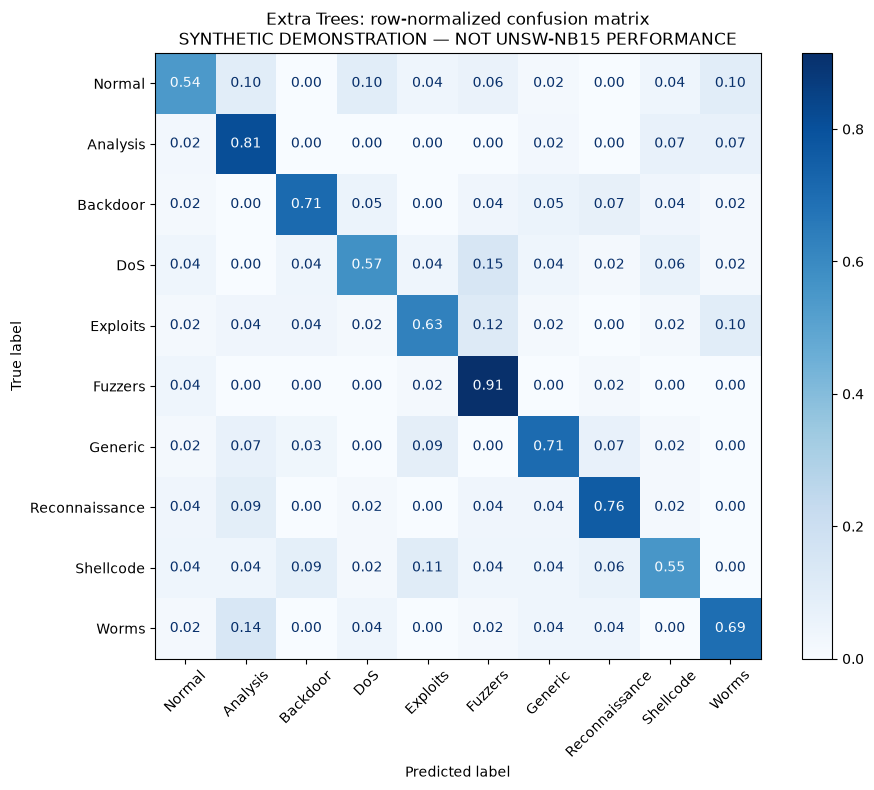

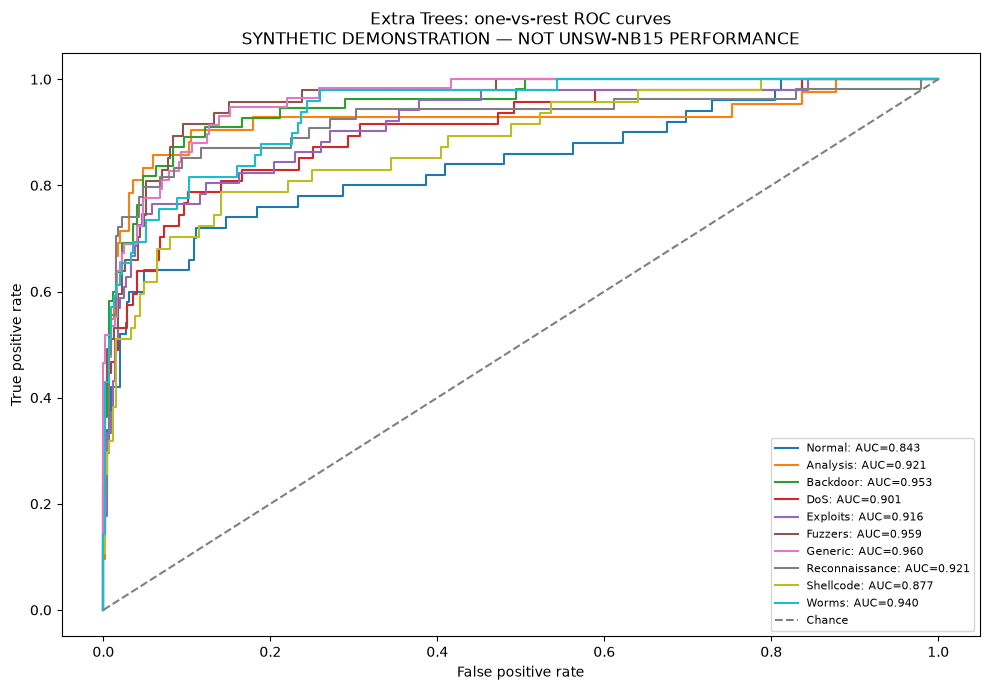

In [10]:
fig, ax = plt.subplots(figsize=(10, 8))
matrix = confusion_matrix(y_test, test_predictions, labels=CLASSES, normalize='true')
ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, values_format='.2f')
ax.set_title(f'{best_name}: row-normalized confusion matrix\n{RUN_LABEL}')
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 7))
for row in test_auc_rows:
    if row['roc_auc_ovr'] is None:
        continue
    label = row['class']
    binary = y_test.to_numpy() == label
    column = list(model_classes).index(label)
    false_positive_rate, true_positive_rate, thresholds = roc_curve(binary, test_probabilities[:, column])
    ax.plot(false_positive_rate, true_positive_rate, label=f"{label}: AUC={row['roc_auc_ovr']:.3f}")
ax.plot([0, 1], [0, 1], '--', color='gray', label='Chance')
ax.set(xlabel='False positive rate', ylabel='True positive rate',
       title=f'{best_name}: one-vs-rest ROC curves\n{RUN_LABEL}')
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'roc_curves.png', dpi=150, bbox_inches='tight')
display(fig)
plt.close(fig)


## 11. Explore global feature importance
Tree impurity importance is associative and can favour high-cardinality features;
it does not explain a particular alert or prove causation. If Logistic Regression
wins, show the highest-ranked validation tree model and identify it explicitly.
Output: top transformed features, source model and global importance plot.


Importance source model: Extra Trees


,feature,importance,model
21,numeric__feature_21,0.049754,Extra Trees
4,numeric__feature_04,0.049709,Extra Trees
15,numeric__feature_15,0.049197,Extra Trees
19,numeric__feature_19,0.048597,Extra Trees
11,numeric__feature_11,0.047866,Extra Trees
8,numeric__feature_08,0.047815,Extra Trees
2,numeric__feature_02,0.047326,Extra Trees
16,numeric__feature_16,0.046976,Extra Trees
20,numeric__feature_20,0.046533,Extra Trees
17,numeric__feature_17,0.045334,Extra Trees


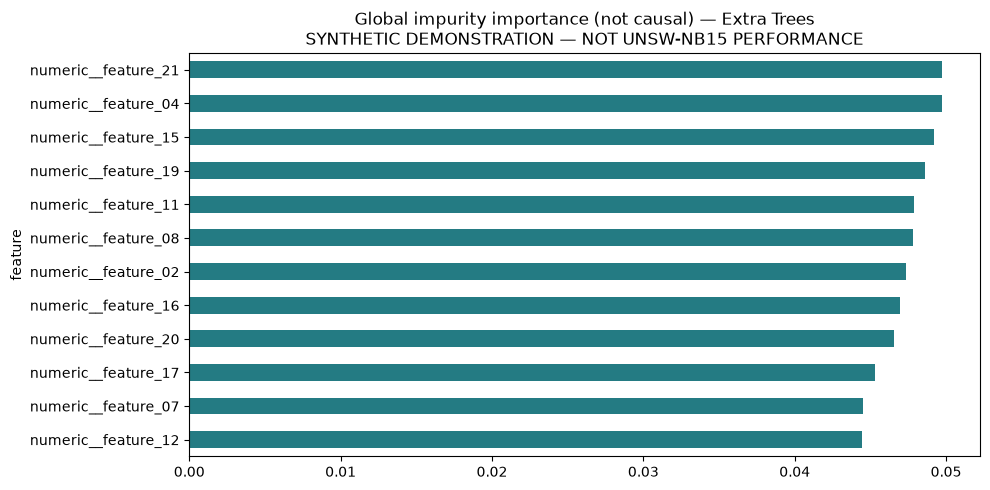

In [11]:
importance_model = best_name
importance_pipeline = winner
if not hasattr(winner.named_steps['classifier'], 'feature_importances_'):
    importance_model = next(name for name in leaderboard.model
                            if hasattr(fitted[name].named_steps['classifier'], 'feature_importances_'))
    importance_pipeline = fitted[importance_model]
importance = pd.DataFrame({
    'feature': importance_pipeline.named_steps['features'].get_feature_names_out(),
    'importance': importance_pipeline.named_steps['classifier'].feature_importances_,
    'model': importance_model,
}).sort_values('importance', ascending=False)
print('Importance source model:', importance_model)
display(importance.head(15))
fig, ax = plt.subplots(figsize=(10, 5))
importance.head(12).iloc[::-1].plot.barh(x='feature', y='importance', ax=ax, legend=False, color='#247b83')
ax.set_title(f'Global impurity importance (not causal) — {importance_model}\n{RUN_LABEL}')
fig.tight_layout()
fig.savefig(OUT / 'feature_importance.png', dpi=150)
display(fig)
plt.close(fig)


## 12. Build an illustrative analyst review queue
Predicted attack categories and uncalibrated maximum class scores are combined
with example severity weights. These hand-assigned priorities are not measured
business risk. Numeric deviations use training statistics only. No blocking occurs.
Output: up to 100 prioritized flows; preview the first ten for human review.


In [12]:
alerts = pd.DataFrame({'flow_index': np.arange(len(X_test)),
                       'predicted_attack': test_predictions,
                       'model_confidence': np.round(test_probabilities.max(axis=1), 4)})
alerts['severity_assumption_0_to_5'] = alerts.predicted_attack.map(SEVERITY)
alerts['priority_score_illustrative'] = (
    alerts.model_confidence * alerts.severity_assumption_0_to_5).round(4)
alerts['needs_human_review'] = (alerts.model_confidence < .60) | (alerts.predicted_attack != 'Normal')
alerts = alerts.sort_values('priority_score_illustrative', ascending=False).head(100).copy()
if numeric_columns:
    training_numeric = X_train[numeric_columns].apply(pd.to_numeric, errors='coerce')
    alert_numeric = X_test.iloc[alerts.flow_index.to_numpy()][numeric_columns].apply(pd.to_numeric, errors='coerce')
    medians = training_numeric.median().fillna(0)
    standard_deviations = training_numeric.std().replace(0, 1).fillna(1)
    deviations = (alert_numeric.fillna(medians) - medians) / standard_deviations
    signals = []
    for _, row in deviations.iterrows():
        largest = row.abs().nlargest(min(3, len(numeric_columns))).index
        signals.append(', '.join(f'{column}({row[column]:+.1f}z)' for column in largest))
    alerts['top_feature_deviations_illustrative'] = signals
else:
    alerts['top_feature_deviations_illustrative'] = 'n/a'
display(alerts.head(10))


,flow_index,predicted_attack,model_confidence,severity_assumption_0_to_5,priority_score_illustrative,needs_human_review,top_feature_deviations_illustrative
112,112,Shellcode,0.6249,5,3.1245,True,"feature_13(-2.4z), feature_04(+2.3z), feature_..."
351,351,Shellcode,0.5778,5,2.8890,True,"feature_21(+2.7z), feature_06(-1.9z), feature_..."
136,136,Shellcode,0.5759,5,2.8795,True,"feature_08(-2.7z), feature_21(+2.0z), feature_..."
214,214,Backdoor,0.5677,5,2.8385,True,"feature_04(-1.7z), feature_18(+1.6z), feature_..."
119,119,Exploits,0.5517,5,2.7585,True,"feature_15(+2.0z), feature_13(+1.8z), feature_..."
123,123,Backdoor,0.5418,5,2.7090,True,"feature_04(-2.5z), feature_05(-1.9z), feature_..."
106,106,Shellcode,0.5147,5,2.5735,True,"feature_21(+2.6z), feature_15(+2.3z), feature_..."
353,353,Shellcode,0.4742,5,2.3710,True,"feature_03(+2.0z), feature_04(+1.8z), feature_..."
90,90,Exploits,0.4740,5,2.3700,True,"feature_06(+2.4z), feature_20(+2.0z), feature_..."
300,300,Worms,0.4715,5,2.3575,True,"feature_05(-2.3z), feature_20(-2.1z), feature_..."


## 13. Export results and record provenance
Notebook results live in `outputs/notebook/`, separate from CLI results in `outputs/`.
Metadata is written last as a completion marker. Raw records are not exported here.
The notebook includes synthetic training previews and inline images for learning.
Before publishing a real/private run, clear notebook outputs and inspect metadata.
Output: artifact manifest and a compact run summary.


In [13]:
leaderboard.to_csv(OUT / 'validation_leaderboard.csv', index=False)
leaderboard.to_csv(OUT / 'model_comparison.csv', index=False)
pd.DataFrame(validation_auc_rows).to_csv(OUT / 'validation_roc_auc.csv', index=False)
pd.DataFrame([test_metrics]).to_csv(OUT / 'heldout_test_metrics.csv', index=False)
pd.DataFrame(test_auc_rows).to_csv(OUT / 'heldout_test_roc_auc.csv', index=False)
importance.to_csv(OUT / 'feature_importance.csv', index=False)
# Neutralize spreadsheet formulas in any string data, without changing numeric values.
export_alerts = alerts.copy()
for column in export_alerts.select_dtypes(include=['object', 'string']).columns:
    export_alerts[column] = export_alerts[column].map(
        lambda value: "'" + value if isinstance(value, str) and value.lstrip().startswith(('=', '+', '-', '@')) else value)
export_alerts.to_csv(OUT / 'example_soc_alerts.csv', index=False)
(OUT / 'classification_report.txt').write_text(
    RUN_LABEL + '\n' + classification_report(y_test, test_predictions, labels=CLASSES, zero_division=0),
    encoding='utf-8')
metadata = {
    'project': 'Axynetra', 'dataset': RUN_LABEL, 'is_synthetic_smoke_test': SMOKE_TEST,
    'seed': SEED, 'versions': versions, 'provenance': provenance,
    'max_train': MAX_TRAIN, 'max_test': MAX_TEST,
    'train_rows': len(train), 'fit_train_rows': len(fit), 'val_rows': len(validation), 'test_rows': len(test),
    'predictor_count': len(features), 'excluded_leakage_columns': sorted(LEAKAGE_COLUMNS),
    'best_model': best_name, 'feature_importance_model': importance_model,
    'validation_split_info': split_info, 'validation_leaderboard': leaderboard.to_dict('records'),
    'heldout_test_evaluation': test_metrics, 'heldout_test_per_class': per_class,
    'heldout_test_roc_auc': test_auc_rows,
    'selection_protocol': 'Validation Macro F1; refit winner on full train; one held-out evaluation per run.',
}
(OUT / 'run_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
display(pd.DataFrame([{'artifact': path.name, 'bytes': path.stat().st_size}
                      for path in sorted(OUT.iterdir()) if path.is_file()]))
print(f'Completed: {RUN_LABEL}')
print(f'Winner: {best_name}; test Macro F1: {test_metrics["macro_f1"]:.4f}; '
      f'test accuracy: {test_metrics["accuracy"]:.4f}')


,artifact,bytes
0,classification_report.txt,857
1,confusion_matrix.png,144596
2,example_soc_alerts.csv,9292
3,feature_importance.csv,1431
4,feature_importance.png,65684
5,heldout_test_metrics.csv,316
6,heldout_test_roc_auc.csv,427
7,model_comparison.csv,865
8,roc_curves.png,106279
9,run_metadata.json,7318


Completed: SYNTHETIC DEMONSTRATION — NOT UNSW-NB15 PERFORMANCE
Winner: Extra Trees; test Macro F1: 0.6828; test accuracy: 0.6880


## 14. Interpretation, use cases and next experiments
- **Teaching:** compare supervised classifiers, preprocessing and validation protocols.
- **Offline benchmark research:** evaluate labelled UNSW-NB15 flows with documented splits.
- **Analyst triage prototype:** illustrate attack categories, review priorities and feature signals.
- **Rare-class study:** inspect Worms/Shellcode recall and macro metrics instead of accuracy alone.

Synthetic results verify software behaviour only. Dataset shift, near-duplicate
flows, class imbalance and uncalibrated probabilities limit operational conclusions.
Real data and independent validation are required before security use. An autoencoder
is a possible future extension, not part of this notebook's implemented pipeline.

References: UNSW-NB15 dataset, Moustafa & Slay (MilCIS, 2015);
scikit-learn Pipeline, ColumnTransformer and roc_auc_score documentation.
